# 方格子 $J_1-J_2$：结果与 benchmark

核查至2026-10-22。方格CT8论文容量恢复训练及终审已完成：J0／160步 E/N=−.66754554±.00036389，J.5／578步 −.48903998±.00026839。新终审原始双流和checkpoint已核验；此前只读收集遗漏了嵌套audit_terminal目录，本次补齐。普通方格ViT没有新8×8态。保留用户隐藏CT系列的作图选择。

单位 $J_1=1$、$S=1/2$、$E/N$，有限体系双周期PBC。误差条为独立链1 SE；精确期望和确定性TN结果不伪造统计误差。不同尺寸更低的能量不等于方法胜出，有限D的无限系统iPEPS也不是有限环面的能量标杆。
整理说明（2026-10-20）：仅保留精选能量benchmark，旧探索图及原notebook副本见归档。本次补齐已完成独立审计，更新数据与来源；不以训练均值替代。


In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 130, 'savefig.dpi': 250, 'axes.grid': False,
    'lines.linewidth': 1.6, 'legend.frameon': False,
})
# 在这里改全局风格；各图的数组、颜色、marker 都可直接修改。
repo = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'su2_nqs').is_dir())
figure_dir = repo/'figures/square_j1j2'
figure_dir.mkdir(parents=True, exist_ok=True)


No event loop hook running.


## 1. $J_2=0,0.5$：不同方法随尺寸的能量

普通Spatial-ViT仍为6×6的J0 step500、J.5 step1250独立审计；没有新的8×8 ViT态。ClebschTree的4×4仅作完整期望校准，8×8采用本次补齐的固定160／578步终态。未完成尺寸收敛，**不将4→8连线拟合为有限尺寸定律**。

| CT8／严格SU(2) | 固定步 | E/N | 链SE | Var/N |
| --- | ---: | ---: | ---: | ---: |
| J2=0 | 160 | −.66754554 | .00036389 | .05964268 |
| J2=.5 | 578 | −.48903998 | .00026839 | .02751598 |

每态8192记录／64独立链／两个独立流。与旧32／450步相比，两点能量与方差均有实质改善；仍比Vieijra–Nys论文高.00583571／.00953033 per site，**尚未复现成功**。旧值留在`square_ct_quality`，对应误差、方差不混配。

容量按论文取τ(j≤2)=16、τ(j>2)=8、jmax=4（代码qmax=8），227958实参数、同层W共享。此阶段没有扩容：显式重置momentum后，16步×256记录SR＋Adam，再112步×4096的clipped Adam；各128次更新均接受。更新部分8.02／11.85 A100小时、各462848训练H中心，另有8192终审，不是完整祖先／排队成本。

J0两个审计流E/N为−.6671352／−.6679559；J.5最上1%记录贡献约38%方差，保留`mixing_certified=false`，链SE不是完全混合证明。完整checkpoint参数、优化器、sampler/RNG与注册身份已本地核验；原始矩重算差0。先前收集器遗漏嵌套`audit_terminal/`，不是任务尚未完成。

保留用户在图中隐藏本项目CT系列的选择；需要显示时手动取消原plot行注释即可。图例统一SU(2)，此处来源是方格二叉ClebschTree。

发表参考：[Vieijra–Nys TableI](https://arxiv.org/html/2104.14869v2#A1.T1) 的8×8总能量除64；[Roth GCNN](https://arxiv.org/html/2211.07749) 的10/12/16；[Spatial-ViT](https://arxiv.org/html/2602.02665v1#S4) 的20×20、J.5完整投影raw值。后者没有可抄录的方格J0点，数组留空。[Hasik et al.](https://arxiv.org/html/2009.02313v2) 提供无限体系D7参考，不当作有限环面标杆。


In [2]:
square_j2_points = np.array([0., .5])
square_vit_L = [np.array([6.]), np.array([6.])]
square_vit_E = [np.array([-.6788438149294413]), np.array([-.5031626699067514])]
square_vit_SE = [np.array([1.3502335046772777e-5]), np.array([4.9716146460136e-5])]

# 2026-10-22核验：J0的8x8为160步，J.5为578步；仅替换匹配终态的E/SE/方差。
square_ct_L = [np.array([8.]), np.array([4., 8.])]
square_ct_E = [np.array([-0.6675455386520357]), np.array([-.5286200451170725, -0.4890399823472083])]
square_ct_SE = [np.array([0.00036388581578978294]), np.array([0., 0.0002683852496981294])]
square_ct_variance = [np.array([0.059642679293470696]), np.array([np.nan, 0.027515981179546657])]
# 上面的0只表示4x4是完整期望、无MC误差，不表示精确基态或零变分误差。

published_ct_L = [np.array([8.]), np.array([8.])]
published_ct_E = [np.array([-43.09640/64]), np.array([-31.90850/64])]
published_ct_SE = [np.array([.00320/64]), np.array([.00420/64])]
published_vit_L = [np.array([], dtype=float), np.array([20.])]
published_vit_E = [np.array([], dtype=float), np.array([-.496732])]
published_vit_SE = [np.array([], dtype=float), np.array([.000001])]
published_gcnn_L = [np.array([], dtype=float), np.array([10., 12., 16.])]
published_gcnn_E = [np.array([], dtype=float), np.array([-.497437, -.496769, -.496509])]
published_gcnn_SE = [np.array([], dtype=float), np.array([.000007, .000009, .000006])]

# 4x4 exact值来自已存小系统基准，不做新ED；6x6 .5为公开有限环面参考。
square_ed_L = [np.array([], dtype=float), np.array([4., 6.])]
square_ed_E = [np.array([], dtype=float), np.array([-8.457923351394845/16, -.503810])]
square_ipeps_D7 = np.array([-.669432, -.496289])
square_qmc_infinite, square_qmc_SE = -.669437, .000005
show_small_exact_calibration = True

# 旧8x8独审保留为质量序列：[J2,step,E/N,SE,Var/N]，不删除不利结果。
square_ct_quality = np.array([[0.,32,-.5042549004497094,.0009046994656504777,.34217019520003833],[.5,450,-.4618029388908283,.0004900750781101544,.05438466689785291],[0, 160, -0.6675455386520357, 0.00036388581578978294, 0.059642679293470696],[0.5, 578, -0.4890399823472083, 0.0002683852496981294, 0.027515981179546657]])
# 新阶段（均128次接受更新）：[J2,parameters,train_H,audit_H,train_seconds]；非完整祖先成本。
square_ct_new_stage_cost = np.array([[0, 227958, 462848, 8192, 28873.24301178404], [0.5, 227958, 462848, 8192, 42676.81452107523]])


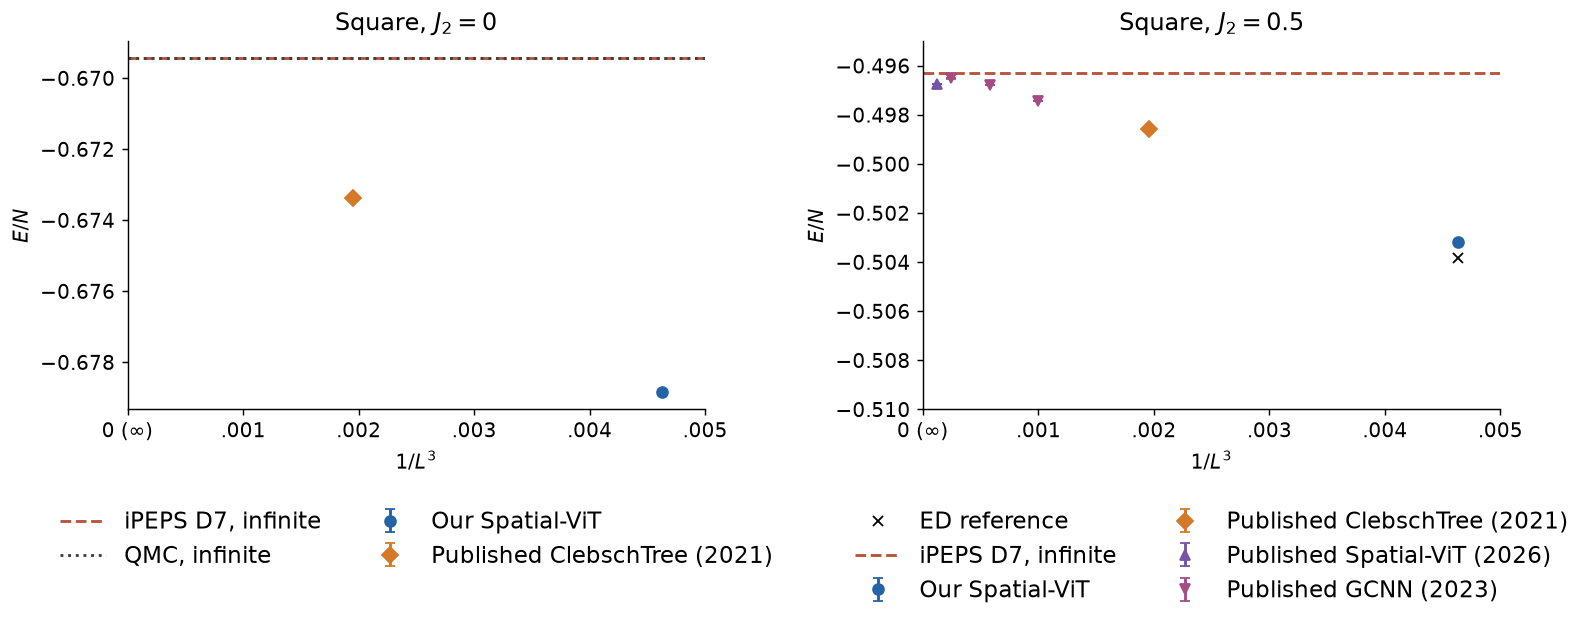

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.2))
for i, ax in enumerate(axes):
    for L, E, SE, marker, color, label in [
        (square_vit_L[i], square_vit_E[i], square_vit_SE[i], 'o', '#2463a6', 'Our Spatial-ViT'),
        # (square_ct_L[i], square_ct_E[i], square_ct_SE[i], 's', '#009E73', 'SU(2)'),
        (published_ct_L[i], published_ct_E[i], published_ct_SE[i], 'D', '#d47928', 'Published ClebschTree (2021)'),
        (published_vit_L[i], published_vit_E[i], published_vit_SE[i], '^', '#7653a6', 'Published Spatial-ViT (2026)'),
        (published_gcnn_L[i], published_gcnn_E[i], published_gcnn_SE[i], 'v', '#a54c82', 'Published GCNN (2023)'),
    ]:
        use = np.ones(L.size, dtype=bool) if show_small_exact_calibration else L > 4
        if use.any():
            assert L.size == E.size == SE.size
            ax.errorbar(L[use]**-3, E[use], yerr=SE[use], fmt=marker,
                        color=color, capsize=3, label=label)
    ed_use = np.ones(square_ed_L[i].size, dtype=bool) if show_small_exact_calibration else square_ed_L[i] > 4
    if ed_use.any():
        ax.plot(square_ed_L[i][ed_use]**-3, square_ed_E[i][ed_use], 'x', color='black', label='ED reference')
    ax.axhline(square_ipeps_D7[i], color='#ba543c', ls='--', label=r'iPEPS D7, infinite')
    if i == 0:
        ax.axhline(square_qmc_infinite, color='.25', ls=':', label='QMC, infinite')
    ax.axvline(0, color='.85', ls=':', lw=1)
    xmax = .0165 if i == 1 and show_small_exact_calibration else .00505
    ax.set(xlabel=r'$1/L^3$', ylabel=r'$E/N$', title=rf'Square, $J_2={square_j2_points[i]:g}$',
           xlim=(-xmax*.035, xmax))
    # if xmax > .01:
    #     ax.set_xticks([0, .005, .010, .015], [r'$0\ (\infty)$', '.005', '.010', '.015'])
    # else:
    #     ax.set_xticks([0, .001, .002, .003, .004, .005], [r'$0\ (\infty)$', '.001', '.002', '.003', '.004', '.005'])
    
    ax.set_xticks([0, .001, .002, .003, .004, .005], [r'$0\ (\infty)$', '.001', '.002', '.003', '.004', '.005'])
    ax.set_xlim(0, .005)
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
    ax.legend(fontsize=12.7, loc='upper center', bbox_to_anchor=(.5, -.22), ncol=2)
axes[1].set_ylim(-0.510,-0.495)
fig.tight_layout()
fig.savefig(figure_dir/'energy_methods_vs_size.pdf')
fig.savefig(figure_dir/'energy_methods_vs_size.png')
plt.show()


## 2. 能量及Néel／stripe序参量随 $J_2$：仅用外推结果

`zero_variance` 表示固定L的质量外推，`L_infinity` 表示有限尺寸外推。我们尚无足够的数据完成这些外推，因此本项目数组留空。默认固定 $6\times6$ 零方差扫描：无数据则跳过作图，不以raw端点替代；可显式切换为热力学图。

采用connected旋转标量 $S_c(k)$，画 $m_k^2=S_c(k)/N$。Néel波矢为 $(\pi,\pi)$，stripe为 $(\pi,0),(0,\pi)$，分别保存；保留on-site方差，普通ViT不自动假定SU(2)。没有外推不填0，不从finite-D非零磁矩直接断言热力学磁序。

尺寸极限从有限对称态的结构因子取得。对已自发破缺的纯态，扣除非零磁矩乘积会移除Bragg贡献，不把其connected残差与这里的序参量混用。

QMC的J0热力学 $m^2=.0942(2)$ 及能量见[2009.02313](https://arxiv.org/html/2009.02313)。Spatial-ViT的J.5 $-.49684(1)$ 是 **20×20的零方差值**，不是热力学能量；下方只在`zero_variance`且`fixed_L=20`时显示。

In [4]:
# 仅作已有结果查阅，不混入下面的外推曲线。
square_raw_J2 = np.array([0., .5])
square_raw_L = 6
square_raw_E = np.array([-.6788438149294413, -.5031626699067514])
square_raw_E_SE = np.array([1.3502335046772777e-5, 4.9716146460136e-5])


In [5]:
coupling_extrapolation = 'zero_variance'  # 固定尺寸；或改为 'L_infinity'
fixed_L = 6
square_zv_J2 = np.array([], dtype=float)
square_zv_E = np.array([], dtype=float)
square_zv_E_SE = np.array([], dtype=float)
square_zv_SN = np.array([], dtype=float)       # 固定L的S_c(pi,pi)，绘图再除L^2
square_zv_SN_SE = np.array([], dtype=float)
square_zv_SM = np.empty((0, 2))                # 列顺序(pi,0),(0,pi)
square_zv_SM_SE = np.empty((0, 2))

square_inf_J2 = np.array([], dtype=float)
square_inf_E = np.array([], dtype=float)
square_inf_E_SE = np.array([], dtype=float)
square_inf_mN2 = np.array([], dtype=float)
square_inf_mN2_SE = np.array([], dtype=float)
square_inf_mM2 = np.empty((0, 2))
square_inf_mM2_SE = np.empty((0, 2))

qmc_inf_J2 = np.array([0.])
qmc_inf_E = np.array([-.669437])
qmc_inf_E_SE = np.array([.000005])
qmc_inf_mN2 = np.array([.0942])
qmc_inf_mN2_SE = np.array([.0002])
pub_vit_zv_J2 = np.array([.5])
pub_vit_zv_L = 20
pub_vit_zv_E = np.array([-.49684])
pub_vit_zv_E_SE = np.array([.00001])


In [6]:
if coupling_extrapolation == 'L_infinity':
    jj, ee, ee_se = square_inf_J2, square_inf_E, square_inf_E_SE
    nn, nn_se, mm, mm_se = square_inf_mN2, square_inf_mN2_SE, square_inf_mM2, square_inf_mM2_SE
    plot_scope = r'$L\to\infty$'
elif coupling_extrapolation == 'zero_variance':
    jj, ee, ee_se = square_zv_J2, square_zv_E, square_zv_E_SE
    nn, nn_se = square_zv_SN/fixed_L**2, square_zv_SN_SE/fixed_L**2
    mm, mm_se = square_zv_SM/fixed_L**2, square_zv_SM_SE/fixed_L**2
    plot_scope = f'zero variance, L={fixed_L}'
else:
    raise ValueError('Choose L_infinity or zero_variance')
assert ee.shape == ee_se.shape == nn.shape == nn_se.shape == jj.shape
assert mm.shape == mm_se.shape == (jj.size, 2)
# 无相应外推数据时不生成空白图；填入数组后自动作图。
if jj.size == 0:
    print(f'No {plot_scope} data yet: coupling plot skipped; arrays and plotting code retained.')
else:
    fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.9))
    for ax, yy, ss, title, ylabel in [
        (axes[0], ee, ee_se, 'Energy', r'$E/N$'),
        (axes[1], nn, nn_se, 'Néel channel', r'$m_N^2=S_c(\pi,\pi)/N$'),
    ]:
        valid = np.isfinite(jj) & np.isfinite(yy) & np.isfinite(ss)
        if valid.any():
            ax.errorbar(jj[valid], yy[valid], yerr=ss[valid], fmt='o-', capsize=3,
                        color='#2463a6', label='Our extrapolation')
        ax.set(title=title, ylabel=ylabel)
    for index, (marker, color) in enumerate(zip(['o', 's'], ['#009E73', '#d47928'])):
        valid = np.isfinite(jj) & np.isfinite(mm[:, index]) & np.isfinite(mm_se[:, index])
        if valid.any():
            axes[2].errorbar(jj[valid], mm[valid, index], yerr=mm_se[valid, index], fmt=marker+'-',
                             color=color, capsize=3, label=['(pi,0)', '(0,pi)'][index])
    axes[2].set(title='Stripe channels', ylabel=r'$m_M^2=S_c(M)/N$')
    if coupling_extrapolation == 'L_infinity':
        axes[0].errorbar(qmc_inf_J2, qmc_inf_E, yerr=qmc_inf_E_SE,
                         fmt='^', capsize=3, color='.25', label='Published QMC')
        axes[1].errorbar(qmc_inf_J2, qmc_inf_mN2, yerr=qmc_inf_mN2_SE,
                         fmt='^', capsize=3, color='.25', label='Published QMC')
    elif fixed_L == pub_vit_zv_L:
        axes[0].errorbar(pub_vit_zv_J2, pub_vit_zv_E, yerr=pub_vit_zv_E_SE,
                         fmt='^', capsize=3, color='#7653a6', label='Published ViT zero variance')
    for ax in axes:
        ax.set(xlabel=r'$J_2/J_1$', xlim=(-.025, .625))
        ax.set_xticks([0, .1, .2, .3, .4, .5, .6])
        if jj.size == 0:
            ax.text(.5, .48, 'Our extrapolation: unavailable', ha='center', transform=ax.transAxes, color='.45', fontsize=9)
        if ax.get_legend_handles_labels()[0]:
            ax.legend(fontsize=8)
    fig.suptitle('Square: '+plot_scope, fontsize=11)
    fig.tight_layout()
    fig.savefig(figure_dir/f'coupling_scan_{coupling_extrapolation}.pdf')
    fig.savefig(figure_dir/f'coupling_scan_{coupling_extrapolation}.png')
    plt.show()


No zero variance, L=6 data yet: coupling plot skipped; arrays and plotting code retained.


## 来源与维护

- 普通ViT：`projects/clebsch_tree_nqs/results/remote_readout_review_20261013/inputs/nqs/square_j0_repair_v6_single_gpu/seed1/audits/step00500/results.json`；J.5为同目录 `square_j05_continue1250_20261012/seed1/audits/step01250/results.json`。
- ClebschTree 4×4：`projects/clebsch_tree_nqs/results/vieijra_nys_reproduction_20261014/square4_j05_adam_reset_x64/results.json`；旧8×8、J.5质量对照：`projects/clebsch_tree_nqs/results/training_dispatch_20261018/parents/square8_j05/audit_step450/audit.json`。新160／578终态见下面2026-10-22核验。
- 新8×8、J0：`projects/clebsch_tree_nqs/results/monitor_20261019/manual_status_20261019T141450Z.json` 的 `square8_j0` 条目，`documents['audit_step32/audit.json']`；远端原件位于 `/home/yx789/nqs-wavefunctions/nqs/training_dispatch_20261018/square8_j0/audit_step32/audit.json`。固定32步、独立种子、无端点择优，Born误差不证明完全混合。
- ED .5/L6：`references/finite_torus_6x6_targets.json`，原文Wang et al. PRX14,031006 AppendixG TableXI。L4为已存exact anchor，无新ED。
- [ClebschTree 2021 TableI](https://arxiv.org/html/2104.14869#A1.T1)、[GCNN 2023 TableI](https://arxiv.org/html/2211.07749)、[Spatial-ViT 2026 SectionIV](https://arxiv.org/html/2602.02665v1#S4)、[iPEPS/QMC参考 2009.02313](https://arxiv.org/html/2009.02313)。

后续每次检查获得新合格独立审计，均同步更新对应数据、来源、成本及图像；无新审计不替换数值。SU(2)统一图例，同协议二叉／三叉取较低独审均值、文字注明，原始结果保留。未来添加数据直接改L/E/SE数组；不定义额外绘图框架。此notebook不训练、不载入checkpoint、不提交远程任务。[三角格 notebook](TRIANGULAR_J1J2_RESULTS.ipynb) 独立管理三角物理与读出。旧文件及原始输出可恢复于 [历史归档](archive/README.md)。
- 2026-10-20同论文容量恢复：[contract](projects/clebsch_tree_nqs/configs/remote/square_paper_continue_20261020/paper_contract.json)、[receipt](projects/clebsch_tree_nqs/results/square_paper_continue_20261020/submission_receipt.json)。原计划目标160／578现已完成，终态已核验并写入数组。

- [2026-10-22补齐的方格终审](projects/clebsch_tree_nqs/results/remote_review_20261022/20261022T171728Z/verified_square_summary.json)：新160／578步的audit_terminal/audit.json、原始双流和checkpoint均在对应子目录；此前收集器只读root级JSON而漏收嵌套终审，本次已经补齐，不再将任务标为在训。旧目标尚未完成的文字保留作历史记录。
